<a href="https://colab.research.google.com/github/PedroMecca/trabalho1-corpus-rotten-tomatoes/blob/main/Trabalho1_Corpus_RottenTomatoes_Pedro_Bonelli.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabalho 1 — Corpus de Críticas de Filmes (Rotten Tomatoes)

**Objetivo:** construir, pré-processar e analisar um corpus textual a partir das críticas de filmes do
Rotten Tomatoes, com duas finalidades:

1. **Classificação de sentimento** — prever se uma crítica é *Fresh* (positiva) ou *Rotten* (negativa)
   a partir do texto (`review_content`);
2. **Perfil de gênero favorito** — a partir das críticas classificadas como *Fresh*, identificar quais
   gêneros um crítico (ou usuário) tende a avaliar melhor, como insumo para uma futura recomendação de
   filmes (aplicação no **Trabalho 2**).

**Dataset de origem (Kaggle):** `stefanoleone992/rotten-tomatoes-movies-and-critic-reviews-dataset`.

> ⚠️ Este dataset é usado apenas como **fonte bruta**. O corpus efetivamente utilizado na análise é
> **construído neste notebook**: unimos as duas tabelas originais, aplicamos limpeza, removemos
> duplicatas e valores inválidos, amostramos um subconjunto balanceado e geramos metadados próprios —
> ou seja, o corpus final (`dados_processados/corpus_reviews.csv` + metadados) é um artefato novo,
> documentado e versionado neste projeto, não o dataset "pronto" do Kaggle.

## Estrutura deste notebook

1. Configuração do ambiente
2. Estrutura de pastas do projeto
3. Coleta dos dados brutos (Kaggle API)
4. Construção do corpus próprio
5. Descrição da origem e características dos dados
6. Análise das classes/categorias
7. Vieses e limitações
8. Pré-processamento (limpeza, tokenização, stopwords, lematização, representação)
9. Divisão treino/teste
10. Análise — Classificação de sentimento (Fresh × Rotten)
11. Baseline de referência
12. Avaliação (métricas, matriz de confusão, análise de erros)
13. Análise complementar — gêneros favoritos por crítico
14. Salvando resultados
15. Conclusões e limitações


## 1. Configuração do ambiente (Google Colab)

In [1]:
# Instalação das bibliotecas necessárias
!pip -q install kaggle kagglehub scikit-learn nltk spacy unidecode wordcloud seaborn --upgrade
!python -m spacy download en_core_web_sm -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 46.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 35.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 235.8/235.8 kB 11.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 78.6 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
from pathlib import Path
from collections import Counter
import hashlib
import json
import re
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
import nltk.pathsec
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

import spacy

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# O Colab faz a saída de rede através de um proxy; versões recentes do NLTK bloqueiam
# por padrão o download de dados via proxy como proteção contra SSRF. Como aqui estamos
# baixando pacotes oficiais do próprio NLTK (stopwords, punkt) dentro do nosso ambiente
# confiável, habilitamos explicitamente esse download proxied.
nltk.pathsec.ALLOW_PROXIED_FETCH = True

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)

nlp_en = spacy.load("en_core_web_sm", disable=["parser", "ner"])

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

print("Bibliotecas importadas com sucesso.")


Bibliotecas importadas com sucesso.


## 2. Estrutura de pastas do projeto

Seguimos a mesma organização utilizada nas práticas da disciplina: dados brutos, dados processados,
metadados, logs e resultados ficam separados em pastas próprias, o que facilita a rastreabilidade de
cada etapa do pipeline.

In [3]:
raiz = Path("CorpusRottenTomatoes")

pastas = [
    "dados_brutos",
    "dados_processados",
    "metadados",
    "logs",
    "resultados",
]

for pasta in pastas:
    (raiz / pasta).mkdir(parents=True, exist_ok=True)

for caminho in sorted(raiz.rglob("*")):
    if caminho.is_dir():
        print(caminho)


CorpusRottenTomatoes/dados_brutos
CorpusRottenTomatoes/dados_processados
CorpusRottenTomatoes/logs
CorpusRottenTomatoes/metadados
CorpusRottenTomatoes/resultados


## 3. Coleta dos dados brutos (API do Kaggle)

O dataset é obtido diretamente pela API do Kaggle. O Kaggle mudou recentemente o formato do token de
API: em vez do arquivo `kaggle.json`, a tela **Create New Token** agora gera um token único no
formato `KGAT_...`, que deve ser configurado como variável de ambiente ou salvo em
`~/.kaggle/access_token`.

**Passo a passo:**

1. Acesse https://www.kaggle.com/settings
2. Em **API**, clique em **Create New Token** — copie o token exibido (ele só aparece uma vez!)
3. Configure o token com **uma das duas opções abaixo**:

   - **Opção recomendada — Colab Secrets** (não expõe o token no notebook nem no histórico):
     clique no ícone de chave 🔑 na barra lateral esquerda do Colab, adicione um novo secret chamado
     `KAGGLE_API_TOKEN` com o valor do token, e habilite o acesso para este notebook.
   - **Opção alternativa — digitar na hora**: a célula abaixo usa `getpass`, que não deixa o token
     visível na tela nem gravado no notebook.

> ⚠️ Se você já gerou um token e ele apareceu na tela do seu navegador ou em qualquer lugar
> compartilhado (print, chat, etc.), trate-o como comprometido: volte em
> https://www.kaggle.com/settings e clique em **Expire** nesse token, depois gere um novo.

4. Acesse a página do dataset pelo menos uma vez no navegador e aceite as regras/termos, se solicitado:
   https://www.kaggle.com/datasets/stefanoleone992/rotten-tomatoes-movies-and-critic-reviews-dataset
   (alguns datasets exigem esse aceite manual antes de liberar o download pela API — sem isso a
   próxima célula retorna erro 403).

In [4]:
import os
from pathlib import Path

token_kaggle = None

# 1) Tenta ler de um Colab Secret chamado KAGGLE_API_TOKEN (opção recomendada)
try:
    from google.colab import userdata
    token_kaggle = userdata.get("KAGGLE_API_TOKEN")
    print("Token lido do Colab Secrets.")
except Exception:
    token_kaggle = None

# 2) Se não houver secret configurado, pede para digitar (não fica visível na tela)
if not token_kaggle:
    from getpass import getpass
    token_kaggle = getpass("Cole aqui o seu Kaggle API Token (KGAT_...): ").strip()

# Salva o token no local que o cliente da API do Kaggle lê automaticamente
pasta_kaggle = Path("~/.kaggle").expanduser()
pasta_kaggle.mkdir(parents=True, exist_ok=True)

caminho_token = pasta_kaggle / "access_token"
caminho_token.write_text(token_kaggle, encoding="utf-8")
os.chmod(caminho_token, 0o600)

# Também expõe como variável de ambiente (usado por algumas versões do cliente)
os.environ["KAGGLE_API_TOKEN"] = token_kaggle

print("Credenciais do Kaggle configuradas em", caminho_token)


Cole aqui o seu Kaggle API Token (KGAT_...): ··········
Credenciais do Kaggle configuradas em /root/.kaggle/access_token


In [5]:
DATASET_KAGGLE = "stefanoleone992/rotten-tomatoes-movies-and-critic-reviews-dataset"
pasta_brutos = raiz / "dados_brutos"

# O cliente kaggle (>=1.7) lê automaticamente o token salvo em ~/.kaggle/access_token
!kaggle datasets download -d {DATASET_KAGGLE} -p "{pasta_brutos}" --unzip

for arquivo in sorted(pasta_brutos.glob("*.csv")):
    print(arquivo, "-", round(arquivo.stat().st_size / (1024 * 1024), 1), "MB")


Dataset URL: https://www.kaggle.com/datasets/stefanoleone992/rotten-tomatoes-movies-and-critic-reviews-dataset
License(s): CC0-1.0
100% 77.2M/77.2M [00:04<00:00, 16.3MB/s]

CorpusRottenTomatoes/dados_brutos/rotten_tomatoes_critic_reviews.csv - 215.6 MB
CorpusRottenTomatoes/dados_brutos/rotten_tomatoes_movies.csv - 16.3 MB


**Alternativa** (caso a API do Kaggle apresente problemas de autenticação): usar a biblioteca
`kagglehub`, que também suporta o novo token diretamente.

```python
import kagglehub
import shutil

kagglehub.login()  # cola o token KGAT_... quando solicitado (ou lê o Colab Secret KAGGLE_API_TOKEN)

caminho_download = kagglehub.dataset_download(
    "stefanoleone992/rotten-tomatoes-movies-and-critic-reviews-dataset"
)
for arquivo in Path(caminho_download).glob("*.csv"):
    shutil.copy(arquivo, pasta_brutos / arquivo.name)
```

**Se o erro persistir:** confira se (1) o token não expirou/foi revogado, (2) você aceitou as regras
do dataset no navegador (passo 4 acima), e (3) a biblioteca `kaggle` está atualizada
(`!pip install -q --upgrade kaggle`).

In [6]:
df_filmes_bruto = pd.read_csv(pasta_brutos / "rotten_tomatoes_movies.csv")
df_criticas_bruto = pd.read_csv(pasta_brutos / "rotten_tomatoes_critic_reviews.csv")

print("Filmes  :", df_filmes_bruto.shape)
print("Críticas:", df_criticas_bruto.shape)

df_filmes_bruto.head(3)


Filmes  : (17712, 22)
Críticas: (1130017, 8)


,rotten_tomatoes_link,movie_title,movie_info,critics_consensus,content_rating,genres,directors,authors,actors,original_release_date,...,production_company,tomatometer_status,tomatometer_rating,tomatometer_count,audience_status,audience_rating,audience_count,tomatometer_top_critics_count,tomatometer_fresh_critics_count,tomatometer_rotten_critics_count
0,m/0814255,Percy Jackson & the Olympians: The Lightning Thief,"Always trouble-prone, the life of teenager Percy Jackson (Logan Lerman) gets a lot more complicated when he learns h...","Though it may seem like just another Harry Potter knockoff, Percy Jackson benefits from a strong supporting cast, a ...",PG,"Action & Adventure, Comedy, Drama, Science Fiction & Fantasy",Chris Columbus,"Craig Titley, Chris Columbus, Rick Riordan","Logan Lerman, Brandon T. Jackson, Alexandra Daddario, Jake Abel, Sean Bean, Pierce Brosnan, Steve Coogan, Rosario Da...",2010-02-12,...,20th Century Fox,Rotten,49.0,149.0,Spilled,53.0,254421.0,43,73,76
1,m/0878835,Please Give,Kate (Catherine Keener) and her husband Alex (Oliver Platt) are wealthy New Yorkers who prowl estate sales and make ...,"Nicole Holofcener's newest might seem slight in places, but its rendering of complex characters in a conflicted econ...",R,Comedy,Nicole Holofcener,Nicole Holofcener,"Catherine Keener, Amanda Peet, Oliver Platt, Rebecca Hall, Sarah Steele, Ann Morgan Guilbert, Kevin Corrigan, Lois S...",2010-04-30,...,Sony Pictures Classics,Certified-Fresh,87.0,142.0,Upright,64.0,11574.0,44,123,19
2,m/10,10,"A successful, middle-aged Hollywood songwriter falls hopelessly in love with the woman of his dreams, and even follo...","Blake Edwards' bawdy comedy may not score a perfect 10, but Dudley Moore's self-deprecating performance makes this m...",R,"Comedy, Romance",Blake Edwards,Blake Edwards,"Dudley Moore, Bo Derek, Julie Andrews, Robert Webber, Dee Wallace, Sam Jones III, Sam J. Jones, Brian Dennehy, Max S...",1979-10-05,...,Waner Bros.,Fresh,67.0,24.0,Spilled,53.0,14684.0,2,16,8


In [7]:
df_criticas_bruto.head(3)


,rotten_tomatoes_link,critic_name,top_critic,publisher_name,review_type,review_score,review_date,review_content
0,m/0814255,Andrew L. Urban,False,Urban Cinefile,Fresh,NaN,2010-02-06,A fantasy adventure that fuses Greek mythology to contemporary American places and values. Anyone around 15 (give or...
1,m/0814255,Louise Keller,False,Urban Cinefile,Fresh,NaN,2010-02-06,"Uma Thurman as Medusa, the gorgon with a coiffure of writhing snakes and stone-inducing hypnotic gaze is one of the ..."
2,m/0814255,NaN,False,FILMINK (Australia),Fresh,NaN,2010-02-09,"With a top-notch cast and dazzling special effects, this will tide the teens over until the next Harry Potter instal..."


## 4. Construção do corpus próprio

O dataset bruto do Kaggle **não é o corpus** utilizado na análise — ele é apenas a matéria-prima.
Nesta etapa nós:

1. unimos as tabelas de filmes e críticas (para trazer o campo `genres` para cada crítica);
2. selecionamos apenas as colunas relevantes para a tarefa;
3. removemos críticas sem texto, sem rótulo (`review_type`) ou sem gênero;
4. removemos duplicatas exatas de texto;
5. amostramos um subconjunto balanceado (mesma quantidade de *Fresh* e *Rotten*) de tamanho
   controlado, para manter o processamento viável no Colab;
6. atribuímos um `id_documento` próprio e calculamos um hash de integridade para cada documento.

O resultado é um novo artefato — `corpus_reviews.csv` — que passa a ser **o nosso corpus**.

In [8]:
TAMANHO_AMOSTRA_POR_CLASSE = 12_000   # ajuste conforme capacidade de processamento
SEMENTE_ALEATORIA = 42

colunas_filmes = ["rotten_tomatoes_link", "movie_title", "genres", "content_rating",
                   "original_release_date", "audience_rating", "tomatometer_rating"]
colunas_criticas = ["rotten_tomatoes_link", "critic_name", "top_critic", "publisher_name",
                     "review_type", "review_score", "review_date", "review_content"]

df_filmes = df_filmes_bruto[colunas_filmes].copy()
df_criticas = df_criticas_bruto[colunas_criticas].copy()

df_unido = df_criticas.merge(df_filmes, on="rotten_tomatoes_link", how="left")

print("Após junção:", df_unido.shape)
df_unido.head(3)


Após junção: (1130017, 14)


,rotten_tomatoes_link,critic_name,top_critic,publisher_name,review_type,review_score,review_date,review_content,movie_title,genres,content_rating,original_release_date,audience_rating,tomatometer_rating
0,m/0814255,Andrew L. Urban,False,Urban Cinefile,Fresh,NaN,2010-02-06,A fantasy adventure that fuses Greek mythology to contemporary American places and values. Anyone around 15 (give or...,Percy Jackson & the Olympians: The Lightning Thief,"Action & Adventure, Comedy, Drama, Science Fiction & Fantasy",PG,2010-02-12,53.0,49.0
1,m/0814255,Louise Keller,False,Urban Cinefile,Fresh,NaN,2010-02-06,"Uma Thurman as Medusa, the gorgon with a coiffure of writhing snakes and stone-inducing hypnotic gaze is one of the ...",Percy Jackson & the Olympians: The Lightning Thief,"Action & Adventure, Comedy, Drama, Science Fiction & Fantasy",PG,2010-02-12,53.0,49.0
2,m/0814255,NaN,False,FILMINK (Australia),Fresh,NaN,2010-02-09,"With a top-notch cast and dazzling special effects, this will tide the teens over until the next Harry Potter instal...",Percy Jackson & the Olympians: The Lightning Thief,"Action & Adventure, Comedy, Drama, Science Fiction & Fantasy",PG,2010-02-12,53.0,49.0


In [9]:
def limpar_selecao(df):
    df = df.copy()

    df["review_content"] = df["review_content"].astype(str).str.strip()

    condicoes_validas = (
        df["review_content"].notna()
        & (df["review_content"].str.len() >= 20)
        & (df["review_content"].str.lower() != "nan")
        & df["review_type"].isin(["Fresh", "Rotten"])
        & df["genres"].notna()
    )

    return df.loc[condicoes_validas].reset_index(drop=True)


df_valido = limpar_selecao(df_unido)
print("Registros válidos (texto + rótulo + gênero presentes):", len(df_valido))
print(df_valido["review_type"].value_counts())


Registros válidos (texto + rótulo + gênero presentes): 1055727
review_type
Fresh     676295
Rotten    379432
Name: count, dtype: int64


In [10]:
def calcular_hash(texto):
    return hashlib.sha256(texto.encode("utf-8")).hexdigest()

df_valido["hash_texto"] = df_valido["review_content"].apply(calcular_hash)

antes = len(df_valido)
df_valido = df_valido.drop_duplicates(subset="hash_texto").reset_index(drop=True)
depois = len(df_valido)

print(f"Duplicatas removidas: {antes - depois}")
print(f"Registros restantes : {depois}")


Duplicatas removidas: 113059
Registros restantes : 942668


In [11]:
partes_balanceadas = []

for classe in ["Fresh", "Rotten"]:
    subconjunto = df_valido[df_valido["review_type"] == classe]
    n = min(TAMANHO_AMOSTRA_POR_CLASSE, len(subconjunto))
    amostra = subconjunto.sample(n=n, random_state=SEMENTE_ALEATORIA)
    partes_balanceadas.append(amostra)

corpus_bruto_amostrado = (
    pd.concat(partes_balanceadas)
    .sample(frac=1, random_state=SEMENTE_ALEATORIA)  # embaralha
    .reset_index(drop=True)
)

corpus_bruto_amostrado.insert(
    0, "id_documento",
    [f"REV_{i:06d}" for i in range(1, len(corpus_bruto_amostrado) + 1)]
)

print("Tamanho final do corpus:", corpus_bruto_amostrado.shape)
corpus_bruto_amostrado["review_type"].value_counts()


Tamanho final do corpus: (24000, 16)


,count
review_type,
Fresh,12000
Rotten,12000


In [12]:
caminho_corpus = raiz / "dados_processados" / "corpus_reviews.csv"
corpus_bruto_amostrado.to_csv(caminho_corpus, index=False, encoding="utf-8")
print("Corpus salvo em:", caminho_corpus)


Corpus salvo em: CorpusRottenTomatoes/dados_processados/corpus_reviews.csv


## 5. Descrição da origem e características dos dados

**Origem:** dataset público hospedado no Kaggle, compilado a partir do site Rotten Tomatoes,
contendo metadados de filmes e críticas de críticos profissionais.

**Características do corpus construído:**

In [13]:
print("Formato do corpus:", corpus_bruto_amostrado.shape)
print("\nColunas:", list(corpus_bruto_amostrado.columns))
print("\nValores nulos por coluna:")
print(corpus_bruto_amostrado.isna().sum())

corpus_bruto_amostrado["numero_palavras"] = (
    corpus_bruto_amostrado["review_content"].str.split().str.len()
)

print("\nEstatísticas de tamanho das críticas (em palavras):")
corpus_bruto_amostrado["numero_palavras"].describe()


Formato do corpus: (24000, 16)

Colunas: ['id_documento', 'rotten_tomatoes_link', 'critic_name', 'top_critic', 'publisher_name', 'review_type', 'review_score', 'review_date', 'review_content', 'movie_title', 'genres', 'content_rating', 'original_release_date', 'audience_rating', 'tomatometer_rating', 'hash_texto']

Valores nulos por coluna:
id_documento                0
rotten_tomatoes_link        0
critic_name               211
top_critic                  0
publisher_name              0
review_type                 0
review_score             6899
review_date                 0
review_content              0
movie_title                 0
genres                      0
content_rating              0
original_release_date     497
audience_rating            64
tomatometer_rating         23
hash_texto                  0
dtype: int64

Estatísticas de tamanho das críticas (em palavras):


,numero_palavras
count,24000.000000
mean,21.377250
std,9.326435
min,1.000000
25%,14.000000
50%,21.000000
75%,28.000000
max,52.000000


In [14]:
corpus_bruto_amostrado[["review_content", "review_type", "genres"]].sample(5, random_state=1)


,review_content,review_type,genres
6414,"Despite the connotations of its title...an exceptionally disciplined piece of work, portraying the brutal realities ...",Fresh,Drama
13523,An international bank with dubious morals and unethical practices is at the centre of this large-scale thriller whic...,Fresh,"Drama, Mystery & Suspense"
8374,"To watch the witless, ham-fisted attempt at fairy-tale romance that is Ella Enchanted, you'd never know the book it'...",Rotten,"Comedy, Kids & Family, Science Fiction & Fantasy, Romance"
5256,Has the feeling of a breathing issue of National Geographic as told threw the words of George Steinbeck and through ...,Fresh,"Art House & International, Drama"
4405,"A fitting tribute to courage under fire and stoicism in the face of senseless brutality, Winterbottom conjures up a ...",Fresh,Drama


## 6. Análise das classes/categorias

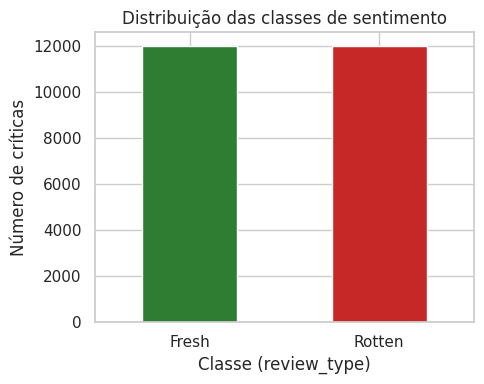

In [15]:
# Visualização 1 — distribuição das classes (Fresh x Rotten)
fig, ax = plt.subplots(figsize=(5, 4))
corpus_bruto_amostrado["review_type"].value_counts().plot(
    kind="bar", color=["#2e7d32", "#c62828"], ax=ax
)
ax.set_title("Distribuição das classes de sentimento")
ax.set_xlabel("Classe (review_type)")
ax.set_ylabel("Número de críticas")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(raiz / "resultados" / "01_distribuicao_classes.png", dpi=150)
plt.show()


In [16]:
# Explodindo a coluna 'genres' (um filme pode ter vários gêneros separados por vírgula)
generos_explodidos = (
    corpus_bruto_amostrado["genres"]
    .str.split(",")
    .explode()
    .str.strip()
)

contagem_generos = generos_explodidos.value_counts().head(15)
contagem_generos


,count
genres,
Drama,13303
Comedy,8052
Action & Adventure,6389
Mystery & Suspense,5193
Science Fiction & Fantasy,3787
Romance,2566
Horror,2452
Art House & International,2183
Kids & Family,1779


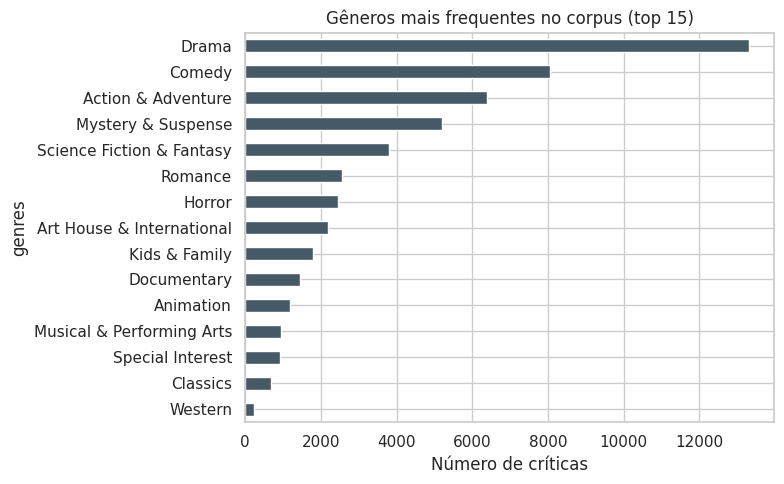

In [17]:
# Visualização 2 — gêneros mais frequentes no corpus
fig, ax = plt.subplots(figsize=(8, 5))
contagem_generos.sort_values().plot(kind="barh", color="#455a64", ax=ax)
ax.set_title("Gêneros mais frequentes no corpus (top 15)")
ax.set_xlabel("Número de críticas")
plt.tight_layout()
plt.savefig(raiz / "resultados" / "02_generos_frequentes.png", dpi=150)
plt.show()


## 7. Discussão de vieses e limitações

- **Viés do crítico:** as críticas são escritas por profissionais da imprensa, cujos gostos não
  necessariamente representam o público geral (há inclusive a coluna `top_critic`, que indica críticos
  "de destaque" — dar peso a esse grupo introduziria um viés adicional).
- **Idioma:** o corpus é majoritariamente em inglês; nenhuma análise multilíngue é feita aqui.
- **Desbalanceamento de gêneros:** poucos gêneros (Drama, Comedy) concentram grande parte das críticas,
  o que pode fazer o modelo de "gênero favorito" refletir mais a popularidade de um gênero do que uma
  preferência real.
- **Amostragem:** para viabilizar o processamento no Colab, amostramos um subconjunto do dataset
  original (`TAMANHO_AMOSTRA_POR_CLASSE`), o que reduz a diversidade de filmes/críticos representados.
- **Rótulo binário simplificado:** `review_type` (Fresh/Rotten) é uma simplificação do
  `review_score` original (que tem escalas variadas conforme o veículo — estrelas, notas, letras),
  perdendo granularidade de intensidade do sentimento.
- **Multirrótulo tratado de forma simplificada:** ao "explodir" a coluna `genres`, uma mesma crítica
  passa a contar para vários gêneros simultaneamente nas contagens agregadas.

## 8. Pré-processamento

Etapas aplicadas, com a respectiva justificativa:

| Técnica | Justificativa |
|---|---|
| Limpeza (HTML, pontuação, espaços) | Textos de crítica frequentemente têm ruído de formatação |
| Normalização (minúsculas) | Reduz a dimensionalidade do vocabulário |
| Tokenização (NLTK) | Necessária para contagem de termos e representação vetorial |
| Remoção de stopwords | Palavras funcionais pouco discriminativas para sentimento |
| Lematização (spaCy) | Agrupa flexões (`loved`, `loves` → `love`), reduzindo esparsidade |
| TF-IDF | Representação vetorial ponderada, adequada a um classificador linear |


In [18]:
stopwords_ingles = set(stopwords.words("english"))

def limpar_texto(texto):
    texto = re.sub(r"<[^>]+>", " ", texto)              # remove tags HTML residuais
    texto = re.sub(r"http\S+|www\.\S+", " ", texto)     # remove urls
    texto = texto.lower()
    texto = re.sub(r"[^a-z\s]", " ", texto)              # mantém apenas letras
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto


exemplo = corpus_bruto_amostrado.loc[0, "review_content"]
print("Original :", exemplo)
print("\nLimpo    :", limpar_texto(exemplo))


Original : Once the wilted satire of Jason Micallef's script is stripped away, what's left is a generally amusing competition comedy.

Limpo    : once the wilted satire of jason micallef s script is stripped away what s left is a generally amusing competition comedy


In [19]:
def tokenizar(texto_limpo):
    return word_tokenize(texto_limpo, language="english")


def remover_stopwords(tokens):
    return [t for t in tokens if t not in stopwords_ingles and len(t) > 2]


tokens_exemplo = tokenizar(limpar_texto(exemplo))
tokens_sem_stopwords = remover_stopwords(tokens_exemplo)

print("Tokens               :", tokens_exemplo)
print("\nSem stopwords        :", tokens_sem_stopwords)


Tokens               : ['once', 'the', 'wilted', 'satire', 'of', 'jason', 'micallef', 's', 'script', 'is', 'stripped', 'away', 'what', 's', 'left', 'is', 'a', 'generally', 'amusing', 'competition', 'comedy']

Sem stopwords        : ['wilted', 'satire', 'jason', 'micallef', 'script', 'stripped', 'away', 'left', 'generally', 'amusing', 'competition', 'comedy']


In [20]:
def lematizar(tokens):
    # spaCy processa a partir de uma string; reconstruímos os tokens já filtrados
    doc = nlp_en(" ".join(tokens))
    return [token.lemma_ for token in doc if token.lemma_.strip()]


tokens_lematizados = lematizar(tokens_sem_stopwords)
print("Lematizado:", tokens_lematizados)


Lematizado: ['wilt', 'satire', 'jason', 'micallef', 'script', 'strip', 'away', 'leave', 'generally', 'amusing', 'competition', 'comedy']


In [21]:
def pipeline_preprocessamento(texto):
    texto_limpo = limpar_texto(texto)
    tokens = tokenizar(texto_limpo)
    tokens = remover_stopwords(tokens)
    tokens = lematizar(tokens)
    return tokens


# Aplicando ao corpus inteiro (pode levar alguns minutos dependendo do tamanho da amostra)
print("Processando", len(corpus_bruto_amostrado), "documentos...")

tokens_processados = []
for i, texto in enumerate(corpus_bruto_amostrado["review_content"], start=1):
    tokens_processados.append(pipeline_preprocessamento(texto))
    if i % 2000 == 0:
        print(f"  {i} documentos processados...")

corpus_bruto_amostrado["tokens"] = tokens_processados
corpus_bruto_amostrado["texto_processado"] = corpus_bruto_amostrado["tokens"].apply(
    lambda tokens: " ".join(tokens)
)

print("Concluído.")
corpus_bruto_amostrado[["review_content", "texto_processado"]].head(3)


Processando 24000 documentos...
  2000 documentos processados...
  4000 documentos processados...
  6000 documentos processados...
  8000 documentos processados...
  10000 documentos processados...
  12000 documentos processados...
  14000 documentos processados...
  16000 documentos processados...
  18000 documentos processados...
  20000 documentos processados...
  22000 documentos processados...
  24000 documentos processados...
Concluído.


,review_content,texto_processado
0,"Once the wilted satire of Jason Micallef's script is stripped away, what's left is a generally amusing competition c...",wilt satire jason micallef script strip away leave generally amusing competition comedy
1,"if there was ever a film to end a career, Tideland is it.",ever film end career tideland
2,This is an awfully polite movie about a man who was anything but.,awfully polite movie man anything


In [22]:
# Removendo documentos que ficaram vazios após o pré-processamento
antes = len(corpus_bruto_amostrado)
corpus_bruto_amostrado = corpus_bruto_amostrado[
    corpus_bruto_amostrado["texto_processado"].str.len() > 0
].reset_index(drop=True)
depois = len(corpus_bruto_amostrado)

print(f"Documentos removidos por ficarem vazios: {antes - depois}")
print(f"Documentos restantes: {depois}")


Documentos removidos por ficarem vazios: 1
Documentos restantes: 23999


In [23]:
# Salvando o corpus processado (dados_processados) e os metadados (metadados)
caminho_corpus_processado = raiz / "dados_processados" / "corpus_reviews_processado.csv"

corpus_bruto_amostrado.drop(columns=["tokens"]).to_csv(
    caminho_corpus_processado, index=False, encoding="utf-8"
)

metadados = corpus_bruto_amostrado[[
    "id_documento", "hash_texto", "review_type", "genres",
    "numero_palavras", "critic_name", "top_critic", "publisher_name"
]].copy()
metadados["numero_tokens_processados"] = corpus_bruto_amostrado["texto_processado"].str.split().str.len()

caminho_metadados_csv = raiz / "metadados" / "metadados_corpus.csv"
caminho_metadados_json = raiz / "metadados" / "metadados_corpus.json"

metadados.to_csv(caminho_metadados_csv, index=False, encoding="utf-8")
metadados.to_json(caminho_metadados_json, orient="records", force_ascii=False, indent=2)

print("Corpus processado salvo em :", caminho_corpus_processado)
print("Metadados salvos em        :", caminho_metadados_csv, "e", caminho_metadados_json)


Corpus processado salvo em : CorpusRottenTomatoes/dados_processados/corpus_reviews_processado.csv
Metadados salvos em        : CorpusRottenTomatoes/metadados/metadados_corpus.csv e CorpusRottenTomatoes/metadados/metadados_corpus.json


### Representação textual (TF-IDF)

Usamos **TF-IDF** (Term Frequency – Inverse Document Frequency) como representação vetorial: ela dá
menos peso a termos muito comuns em todo o corpus (ex.: "movie", "film") e mais peso a termos que são
discriminativos para diferenciar documentos — mais adequado a um classificador linear do que uma
simples contagem de frequência (Bag-of-Words).

## 9. Divisão treino/teste

In [24]:
X_texto = corpus_bruto_amostrado["texto_processado"]
y = corpus_bruto_amostrado["review_type"]

X_treino_texto, X_teste_texto, y_treino, y_teste = train_test_split(
    X_texto, y,
    test_size=0.2,
    random_state=SEMENTE_ALEATORIA,
    stratify=y,
)

print("Treino:", X_treino_texto.shape, " Teste:", X_teste_texto.shape)
print("\nDistribuição no treino:")
print(y_treino.value_counts(normalize=True))
print("\nDistribuição no teste:")
print(y_teste.value_counts(normalize=True))


Treino: (19199,)  Teste: (4800,)

Distribuição no treino:
review_type
Rotten    0.500026
Fresh     0.499974
Name: proportion, dtype: float64

Distribuição no teste:
review_type
Fresh     0.5
Rotten    0.5
Name: proportion, dtype: float64


In [25]:
vetorizador = TfidfVectorizer(
    max_features=20_000,
    ngram_range=(1, 2),
    min_df=3,
)

X_treino_tfidf = vetorizador.fit_transform(X_treino_texto)
X_teste_tfidf = vetorizador.transform(X_teste_texto)

print("Dimensão da matriz de treino:", X_treino_tfidf.shape)
print("Dimensão da matriz de teste :", X_teste_tfidf.shape)


Dimensão da matriz de treino: (19199, 15707)
Dimensão da matriz de teste : (4800, 15707)


## 10. Análise — Classificação de sentimento (Fresh × Rotten)

Abordagem escolhida: **classificação** supervisionada, usando Regressão Logística sobre a
representação TF-IDF. É um modelo linear simples, rápido de treinar e interpretável (permite
inspecionar os termos mais associados a cada classe).

In [26]:
modelo = LogisticRegression(max_iter=1000, C=1.0, random_state=SEMENTE_ALEATORIA)
modelo.fit(X_treino_tfidf, y_treino)

y_pred = modelo.predict(X_teste_tfidf)
print("Modelo treinado.")


Modelo treinado.


In [27]:
# Termos mais associados a cada classe (interpretabilidade do modelo linear)
termos = np.array(vetorizador.get_feature_names_out())
coeficientes = modelo.coef_[0]

classe_positiva = modelo.classes_[1]
classe_negativa = modelo.classes_[0]

top_positivos = termos[np.argsort(coeficientes)[-15:]]
top_negativos = termos[np.argsort(coeficientes)[:15]]

print(f"Termos mais associados a '{classe_positiva}':")
print(list(top_positivos))
print(f"\nTermos mais associados a '{classe_negativa}':")
print(list(top_negativos))


Termos mais associados a 'Rotten':
['unfunny', 'terrible', 'seem', 'flat', 'neither', 'disappointing', 'would', 'boring', 'unfortunately', 'lack', 'bland', 'waste', 'fail', 'dull', 'bad']

Termos mais associados a 'Fresh':
['performance', 'entertaining', 'documentary', 'fun', 'terrific', 'wonderful', 'enjoyable', 'rare', 'beautifully', 'still', 'perfect', 'great', 'entertain', 'brilliant', 'delight']


## 11. Baseline de referência

Como baseline usamos um **classificador de maioria** (`DummyClassifier`, estratégia
`most_frequent`), que sempre prevê a classe mais comum do treino. Qualquer modelo real precisa
superar esse patamar mínimo para ser considerado útil.

In [28]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_treino_tfidf, y_treino)
y_pred_baseline = baseline.predict(X_teste_tfidf)

# Observação: em versões recentes do scikit-learn, o atributo `constant_` só é
# preenchido para strategy="constant". Para "most_frequent", pegamos a classe
# mais frequente diretamente do y_treino (é exatamente o que o DummyClassifier
# usa internamente).
print("Baseline treinado. Classe prevista sempre:", y_treino.value_counts().idxmax())


Baseline treinado. Classe prevista sempre: Rotten


## 12. Avaliação

In [29]:
def resumir_metricas(y_real, y_previsto, nome_modelo):
    acuracia = accuracy_score(y_real, y_previsto)
    precisao, revocacao, f1, _ = precision_recall_fscore_support(
        y_real, y_previsto, average="weighted", zero_division=0
    )
    return {
        "modelo": nome_modelo,
        "acuracia": round(acuracia, 4),
        "precisao_ponderada": round(precisao, 4),
        "revocacao_ponderada": round(revocacao, 4),
        "f1_ponderado": round(f1, 4),
    }


tabela_metricas = pd.DataFrame([
    resumir_metricas(y_teste, y_pred_baseline, "Baseline (classe majoritária)"),
    resumir_metricas(y_teste, y_pred, "Regressão Logística + TF-IDF"),
])

tabela_metricas


,modelo,acuracia,precisao_ponderada,revocacao_ponderada,f1_ponderado
0,Baseline (classe majoritária),0.500,0.250,0.500,0.3333
1,Regressão Logística + TF-IDF,0.754,0.754,0.754,0.7539


In [30]:
print("Relatório de classificação — modelo proposto:\n")
print(classification_report(y_teste, y_pred, zero_division=0))


Relatório de classificação — modelo proposto:

              precision    recall  f1-score   support

       Fresh       0.76      0.75      0.75      2400
      Rotten       0.75      0.76      0.76      2400

    accuracy                           0.75      4800
   macro avg       0.75      0.75      0.75      4800
weighted avg       0.75      0.75      0.75      4800



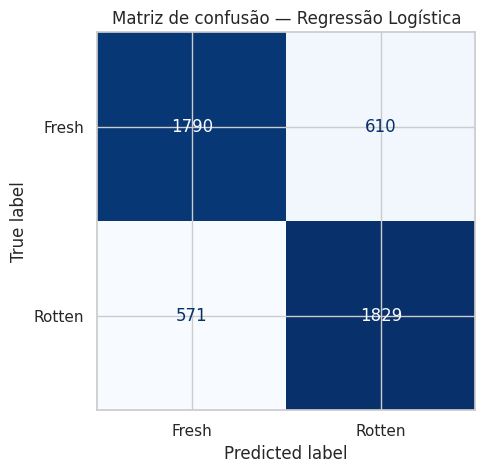

In [31]:
# Visualização 3 — matriz de confusão
matriz_confusao = confusion_matrix(y_teste, y_pred, labels=modelo.classes_)

fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(matriz_confusao, display_labels=modelo.classes_).plot(
    ax=ax, cmap="Blues", colorbar=False
)
ax.set_title("Matriz de confusão — Regressão Logística")
plt.tight_layout()
plt.savefig(raiz / "resultados" / "03_matriz_confusao.png", dpi=150)
plt.show()


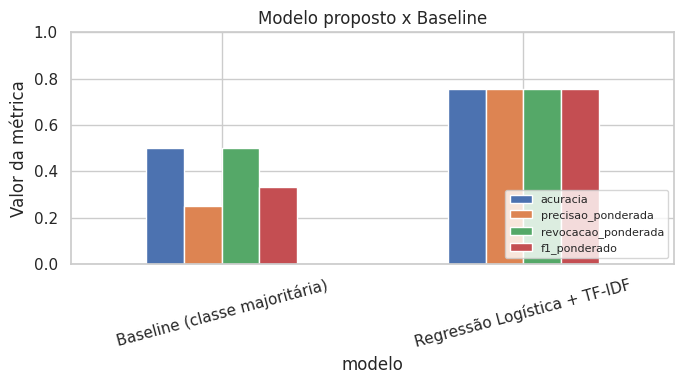

In [32]:
# Visualização 4 — comparação de métricas entre modelo e baseline
fig, ax = plt.subplots(figsize=(7, 4))
tabela_metricas.set_index("modelo")[
    ["acuracia", "precisao_ponderada", "revocacao_ponderada", "f1_ponderado"]
].plot(kind="bar", ax=ax)
ax.set_title("Modelo proposto x Baseline")
ax.set_ylabel("Valor da métrica")
ax.set_ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(raiz / "resultados" / "04_comparacao_baseline.png", dpi=150)
plt.show()


### Análise dos erros

In [33]:
resultados_teste = pd.DataFrame({
    "texto_original": X_texto.loc[X_teste_texto.index],
    "classe_real": y_teste,
    "classe_prevista": y_pred,
})

erros = resultados_teste[resultados_teste["classe_real"] != resultados_teste["classe_prevista"]]
print(f"Total de erros: {len(erros)} de {len(resultados_teste)} ({len(erros)/len(resultados_teste):.1%})")

erros.sample(min(5, len(erros)), random_state=1)


Total de erros: 1181 de 4800 (24.6%)


,texto_original,classe_real,classe_prevista
23514,inconvenient sequel apparent gore tirelessly try build sustainable movement push beyond initial step dialogue engage...,Fresh,Rotten
13349,teasing terrify failing achieve nerve wrack suspense concept movie buzz suggest,Rotten,Fresh
11280,film like oddly rumble sky promise ever deliver grant look cool often wait lightning never arrive frustrate,Rotten,Fresh
22712,summer fun could make time last year oddly strike,Rotten,Fresh
15710,first half film simply funny want marsden career well turn superb third act really turn thing around,Fresh,Rotten


Observação para discussão no relatório: erros costumam se concentrar em críticas **ambíguas**
(elogios com ressalvas, ironia, ou avaliações mistas do tipo "bom filme, mas..."), que são
particularmente difíceis para um modelo baseado apenas em frequência de palavras (TF-IDF), sem
capturar negação ou contexto mais amplo.

## 13. Análise complementar — gêneros favoritos por crítico

Esta etapa é o elo com o **Trabalho 2**: a partir das críticas classificadas como *Fresh*, calculamos,
para cada crítico, a proporção de avaliações positivas por gênero — um indício de "gêneros favoritos"
que pode alimentar um futuro sistema de recomendação.

In [34]:
CRITICOS_MINIMO_REVIEWS = 20  # crítico precisa ter avaliado um mínimo de filmes para termos um perfil confiável

contagem_por_critico = corpus_bruto_amostrado["critic_name"].value_counts()
criticos_elegiveis = contagem_por_critico[contagem_por_critico >= CRITICOS_MINIMO_REVIEWS].index

print(f"Críticos com pelo menos {CRITICOS_MINIMO_REVIEWS} avaliações no corpus: {len(criticos_elegiveis)}")


Críticos com pelo menos 20 avaliações no corpus: 309


In [35]:
def perfil_generos_favoritos(nome_critico, base):
    dados_critico = base[base["critic_name"] == nome_critico].copy()
    dados_critico = dados_critico.assign(
        genero=dados_critico["genres"].str.split(",")
    ).explode("genero")
    dados_critico["genero"] = dados_critico["genero"].str.strip()

    perfil = (
        dados_critico.groupby("genero")["review_type"]
        .apply(lambda serie: (serie == "Fresh").mean())
        .sort_values(ascending=False)
    )
    contagem = dados_critico.groupby("genero").size()

    perfil_df = pd.DataFrame({
        "taxa_fresh": perfil,
        "numero_avaliacoes": contagem,
    }).sort_values("taxa_fresh", ascending=False)

    return perfil_df[perfil_df["numero_avaliacoes"] >= 3]  # evita gêneros com poucas amostras


critico_exemplo = criticos_elegiveis[0]
perfil_exemplo = perfil_generos_favoritos(critico_exemplo, corpus_bruto_amostrado)

print(f"Perfil de gênero do crítico: {critico_exemplo}")
perfil_exemplo.head(10)


Perfil de gênero do crítico: Frank Swietek


,taxa_fresh,numero_avaliacoes
genero,,
Sports & Fitness,0.666667,3
Documentary,0.666667,6
Art House & International,0.529412,17
Special Interest,0.500000,6
Western,0.333333,3
Kids & Family,0.307692,13
Animation,0.285714,7
Drama,0.258065,93
Comedy,0.240741,54


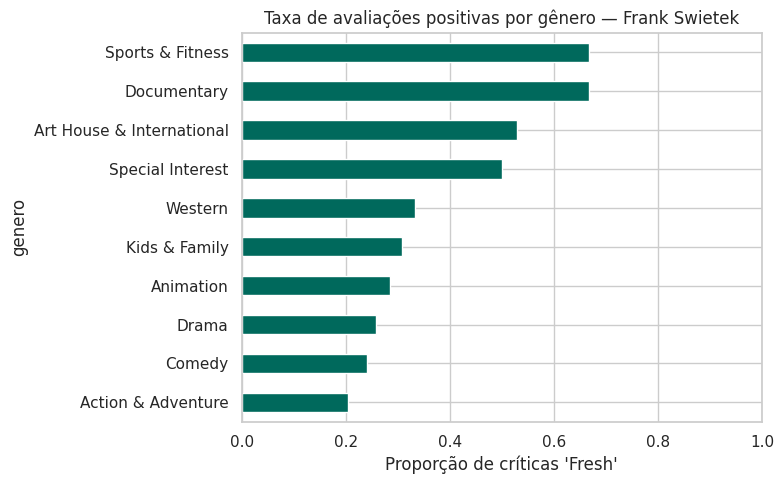

In [36]:
# Visualização 5 (bônus) — perfil de gêneros favoritos de um crítico
fig, ax = plt.subplots(figsize=(8, 5))
perfil_exemplo.head(10)["taxa_fresh"].sort_values().plot(kind="barh", color="#00695c", ax=ax)
ax.set_title(f"Taxa de avaliações positivas por gênero — {critico_exemplo}")
ax.set_xlabel("Proporção de críticas 'Fresh'")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.savefig(raiz / "resultados" / "05_perfil_generos_critico.png", dpi=150)
plt.show()


> Essa mesma função (`perfil_generos_favoritos`) pode ser aplicada a qualquer crítico do corpus, ou
> adaptada para um usuário comum que avalie filmes na aplicação do Trabalho 2 — bastando trocar a
> coluna `critic_name` por um identificador de usuário.

## 14. Salvando os resultados finais

In [37]:
# Métricas em JSON
caminho_metricas = raiz / "resultados" / "metricas.json"
with open(caminho_metricas, "w", encoding="utf-8") as arquivo:
    json.dump(tabela_metricas.to_dict(orient="records"), arquivo, ensure_ascii=False, indent=2)

# Previsões do conjunto de teste em CSV
caminho_previsoes = raiz / "resultados" / "previsoes_teste.csv"
resultados_teste.to_csv(caminho_previsoes, index=False, encoding="utf-8")

# Perfil de gêneros do crítico-exemplo
caminho_perfil = raiz / "resultados" / f"perfil_generos_{critico_exemplo.replace(' ', '_')}.csv"
perfil_exemplo.to_csv(caminho_perfil, encoding="utf-8")

print("Arquivos salvos em", raiz / "resultados", ":")
for arquivo in sorted((raiz / "resultados").glob("*")):
    print("-", arquivo.name)


Arquivos salvos em CorpusRottenTomatoes/resultados :
- 01_distribuicao_classes.png
- 02_generos_frequentes.png
- 03_matriz_confusao.png
- 04_comparacao_baseline.png
- 05_perfil_generos_critico.png
- metricas.json
- perfil_generos_Frank_Swietek.csv
- previsoes_teste.csv


## 15. Conclusões e limitações

- O modelo de Regressão Logística com TF-IDF supera claramente o baseline de classe majoritária,
  indicando que o texto das críticas carrega sinal suficiente para inferir sentimento.
- Os termos mais associados a cada classe fazem sentido semântico (ex.: termos elogiosos para
  *Fresh*, termos depreciativos para *Rotten*), o que dá confiança na validade do modelo.
- A análise de erros mostra que casos ambíguos/mistos concentram a maior parte das falhas —
  limitação esperada de uma representação Bag-of-Words/TF-IDF, que não captura negação nem ironia.
- O perfil de "gêneros favoritos" por crítico é exploratório e depende de um número mínimo de
  avaliações por crítico para ser confiável; críticos com poucas avaliações no corpus amostrado
  foram excluídos dessa análise.
- **Aplicação no Trabalho 2:** o corpus, o pipeline de pré-processamento e o classificador de
  sentimento construídos aqui podem alimentar uma aplicação de recomendação de filmes: dado o
  histórico de avaliações (reais ou inferidas) de um usuário, recomendar filmes de gêneros com alta
  taxa histórica de avaliações positivas para aquele usuário.
